In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import mlflow
import mlflow.sklearn
from mlflow import MlflowClient

from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from imblearn.over_sampling import RandomOverSampler

df=pd.read_csv("../data/dataset-diabete.csv")

In [2]:
print(df.shape)
print("\n")
print(df.dtypes)
print("\n")
print(df.info())
print("\n")
df.head()

(768, 9)


Unnamed: 0                    int64
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                768 non-null    int64  
 1   Pregnancies               768 non-null    int64  
 2   Glucose                   768 non-null    int64  
 3   BloodPressure             768 non-null    int64  
 4   SkinThickness             768 non-null    int64  
 5   Insulin                   768 non-null    int64  
 6   BMI                       768 non-null    float64
 7   DiabetesPedigreeFunction  768 non-null    float64
 8   A

,Unnamed: 0,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0,6,148,72,35,0,33.6,0.627,50
1,1,1,85,66,29,0,26.6,0.351,31
2,2,8,183,64,0,0,23.3,0.672,32
3,3,1,89,66,23,94,28.1,0.167,21
4,4,0,137,40,35,168,43.1,2.288,33


In [3]:
df.drop(columns="Unnamed: 0", inplace=True)
print("Duplicate rows:", df.duplicated().sum())
df.isna().sum()
df.describe(include="all").T


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00


In [4]:

cols_with_fake_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df[cols_with_fake_zeros] = df[cols_with_fake_zeros].replace(0, np.nan)
print(df.isna().sum())

scaler = StandardScaler()
scaled = scaler.fit_transform(df)

knn = KNNImputer(n_neighbors=5)
filled = knn.fit_transform(scaled)

df = pd.DataFrame(scaler.inverse_transform(filled), columns=df.columns)
print(df.isna().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [5]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,264.8,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,65.2,26.6,0.351,31.0
2,8.0,183.0,64.0,30.6,198.2,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0
...,...,...,...,...,...,...,...,...
763,10.0,101.0,76.0,48.0,180.0,32.9,0.171,63.0
764,2.0,122.0,70.0,27.0,128.2,36.8,0.340,27.0
765,5.0,121.0,72.0,23.0,112.0,26.2,0.245,30.0
766,1.0,126.0,60.0,27.2,153.6,30.1,0.349,47.0


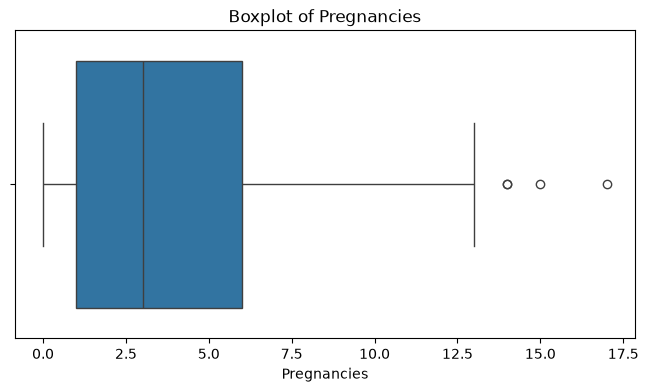

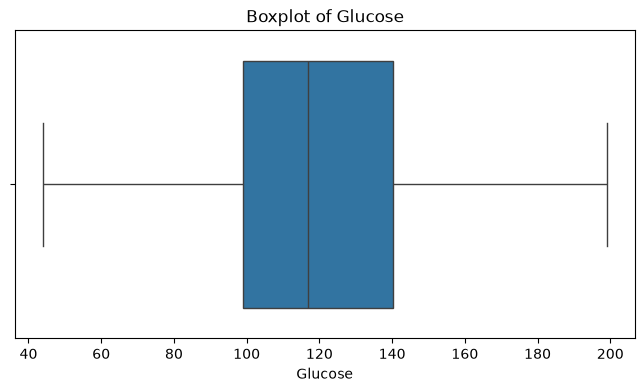

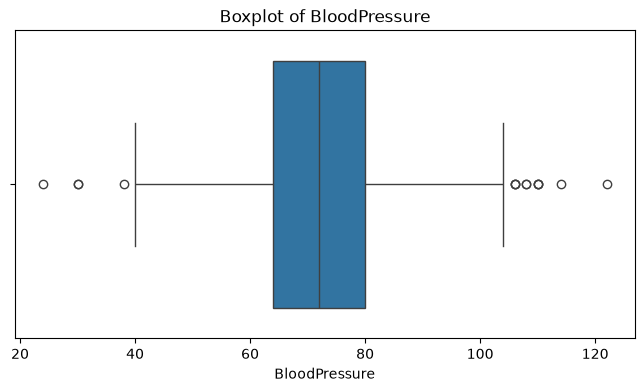

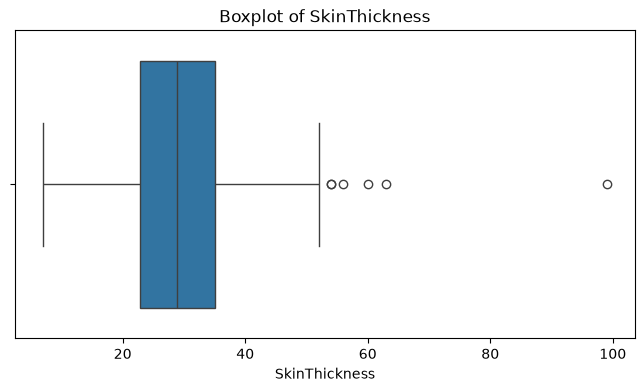

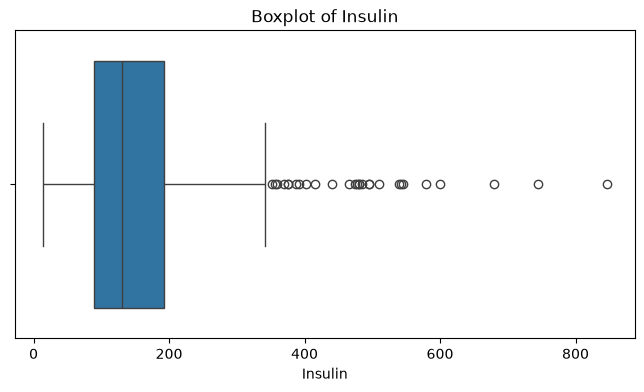

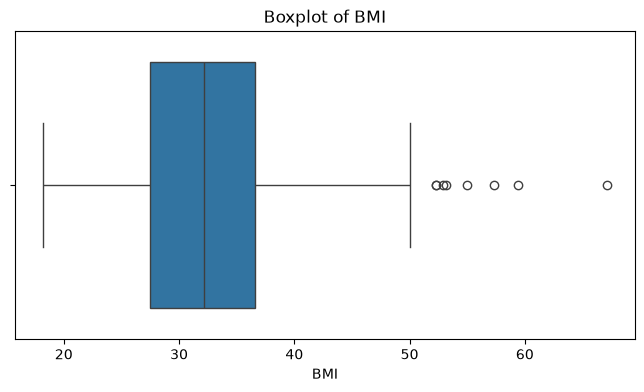

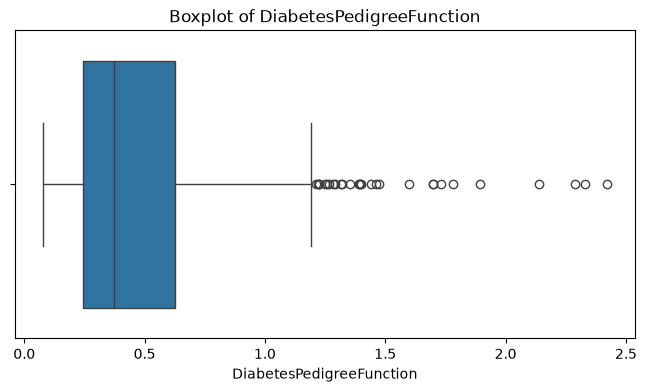

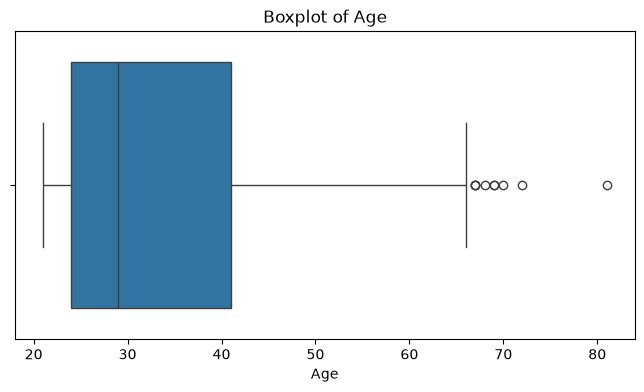

In [6]:
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
for col in cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.594271,30.473439,44.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,72.386719,12.193297,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,28.998698,9.466083,7.000,22.80000,28.8000,35.00000,99.00
Insulin,768.0,153.701562,97.815755,14.000,89.40000,130.0000,192.40000,846.00
BMI,768.0,32.428411,6.890396,18.200,27.50000,32.1900,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00


In [8]:
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, "lower:", lower, "upper:", upper, "outliers:", len(outliers))

Pregnancies lower: -6.5 upper: 13.5 outliers: 4
Glucose lower: 37.125 upper: 202.125 outliers: 0
BloodPressure lower: 40.0 upper: 104.0 outliers: 14
SkinThickness lower: 4.5000000000000036 upper: 53.3 outliers: 6
Insulin lower: -65.09999999999994 upper: 346.8999999999999 outliers: 28
BMI lower: 13.849999999999998 upper: 50.25 outliers: 8
DiabetesPedigreeFunction lower: -0.32999999999999996 upper: 1.2 outliers: 29
Age lower: -1.5 upper: 66.5 outliers: 9


In [9]:
df["BloodPressure"] = df["BloodPressure"].clip(lower=40, upper=120)
df["BMI"] = df["BMI"].clip(lower=15, upper=50)
df["Glucose"] = df["Glucose"].clip(lower=40, upper=300)
df["SkinThickness"] = df["SkinThickness"].clip(lower=5, upper=60)
df["Insulin"] = df["Insulin"].clip(lower=15, upper=550)

print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.594271      72.433594      28.944010  152.792708   
std       3.369578   30.473439      12.025469       9.176805   93.030711   
min       0.000000   44.000000      40.000000       7.000000   15.000000   
25%       1.000000   99.000000      64.000000      22.800000   89.400000   
50%       3.000000  117.000000      72.000000      28.800000  130.000000   
75%       6.000000  140.250000      80.000000      35.000000  192.400000   
max      17.000000  199.000000     120.000000      60.000000  550.000000   

              BMI  DiabetesPedigreeFunction         Age  
count  768.000000                768.000000  768.000000  
mean    32.363958                  0.471876   33.240885  
std      6.675981                  0.331329   11.760232  
min     18.200000                  0.078000   21.000000  
25%     27.500000        

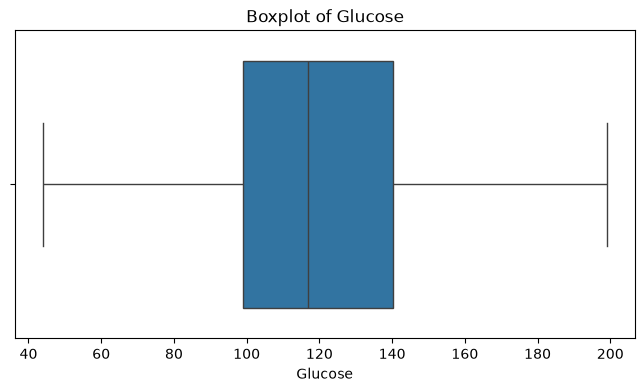

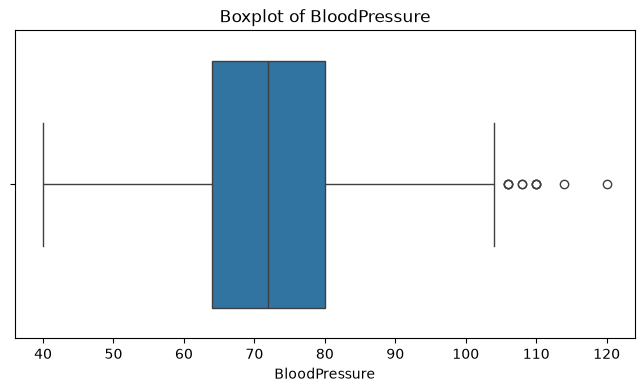

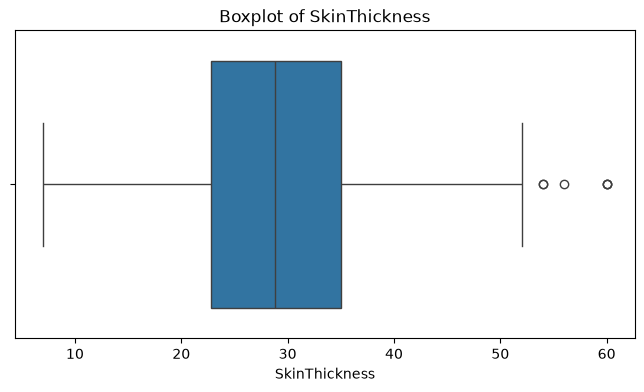

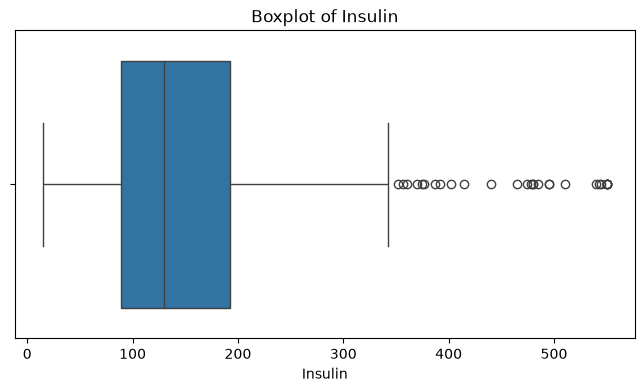

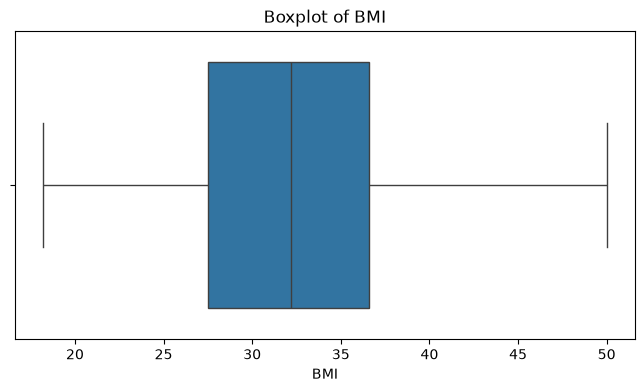

In [10]:
cols1 = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in cols1:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

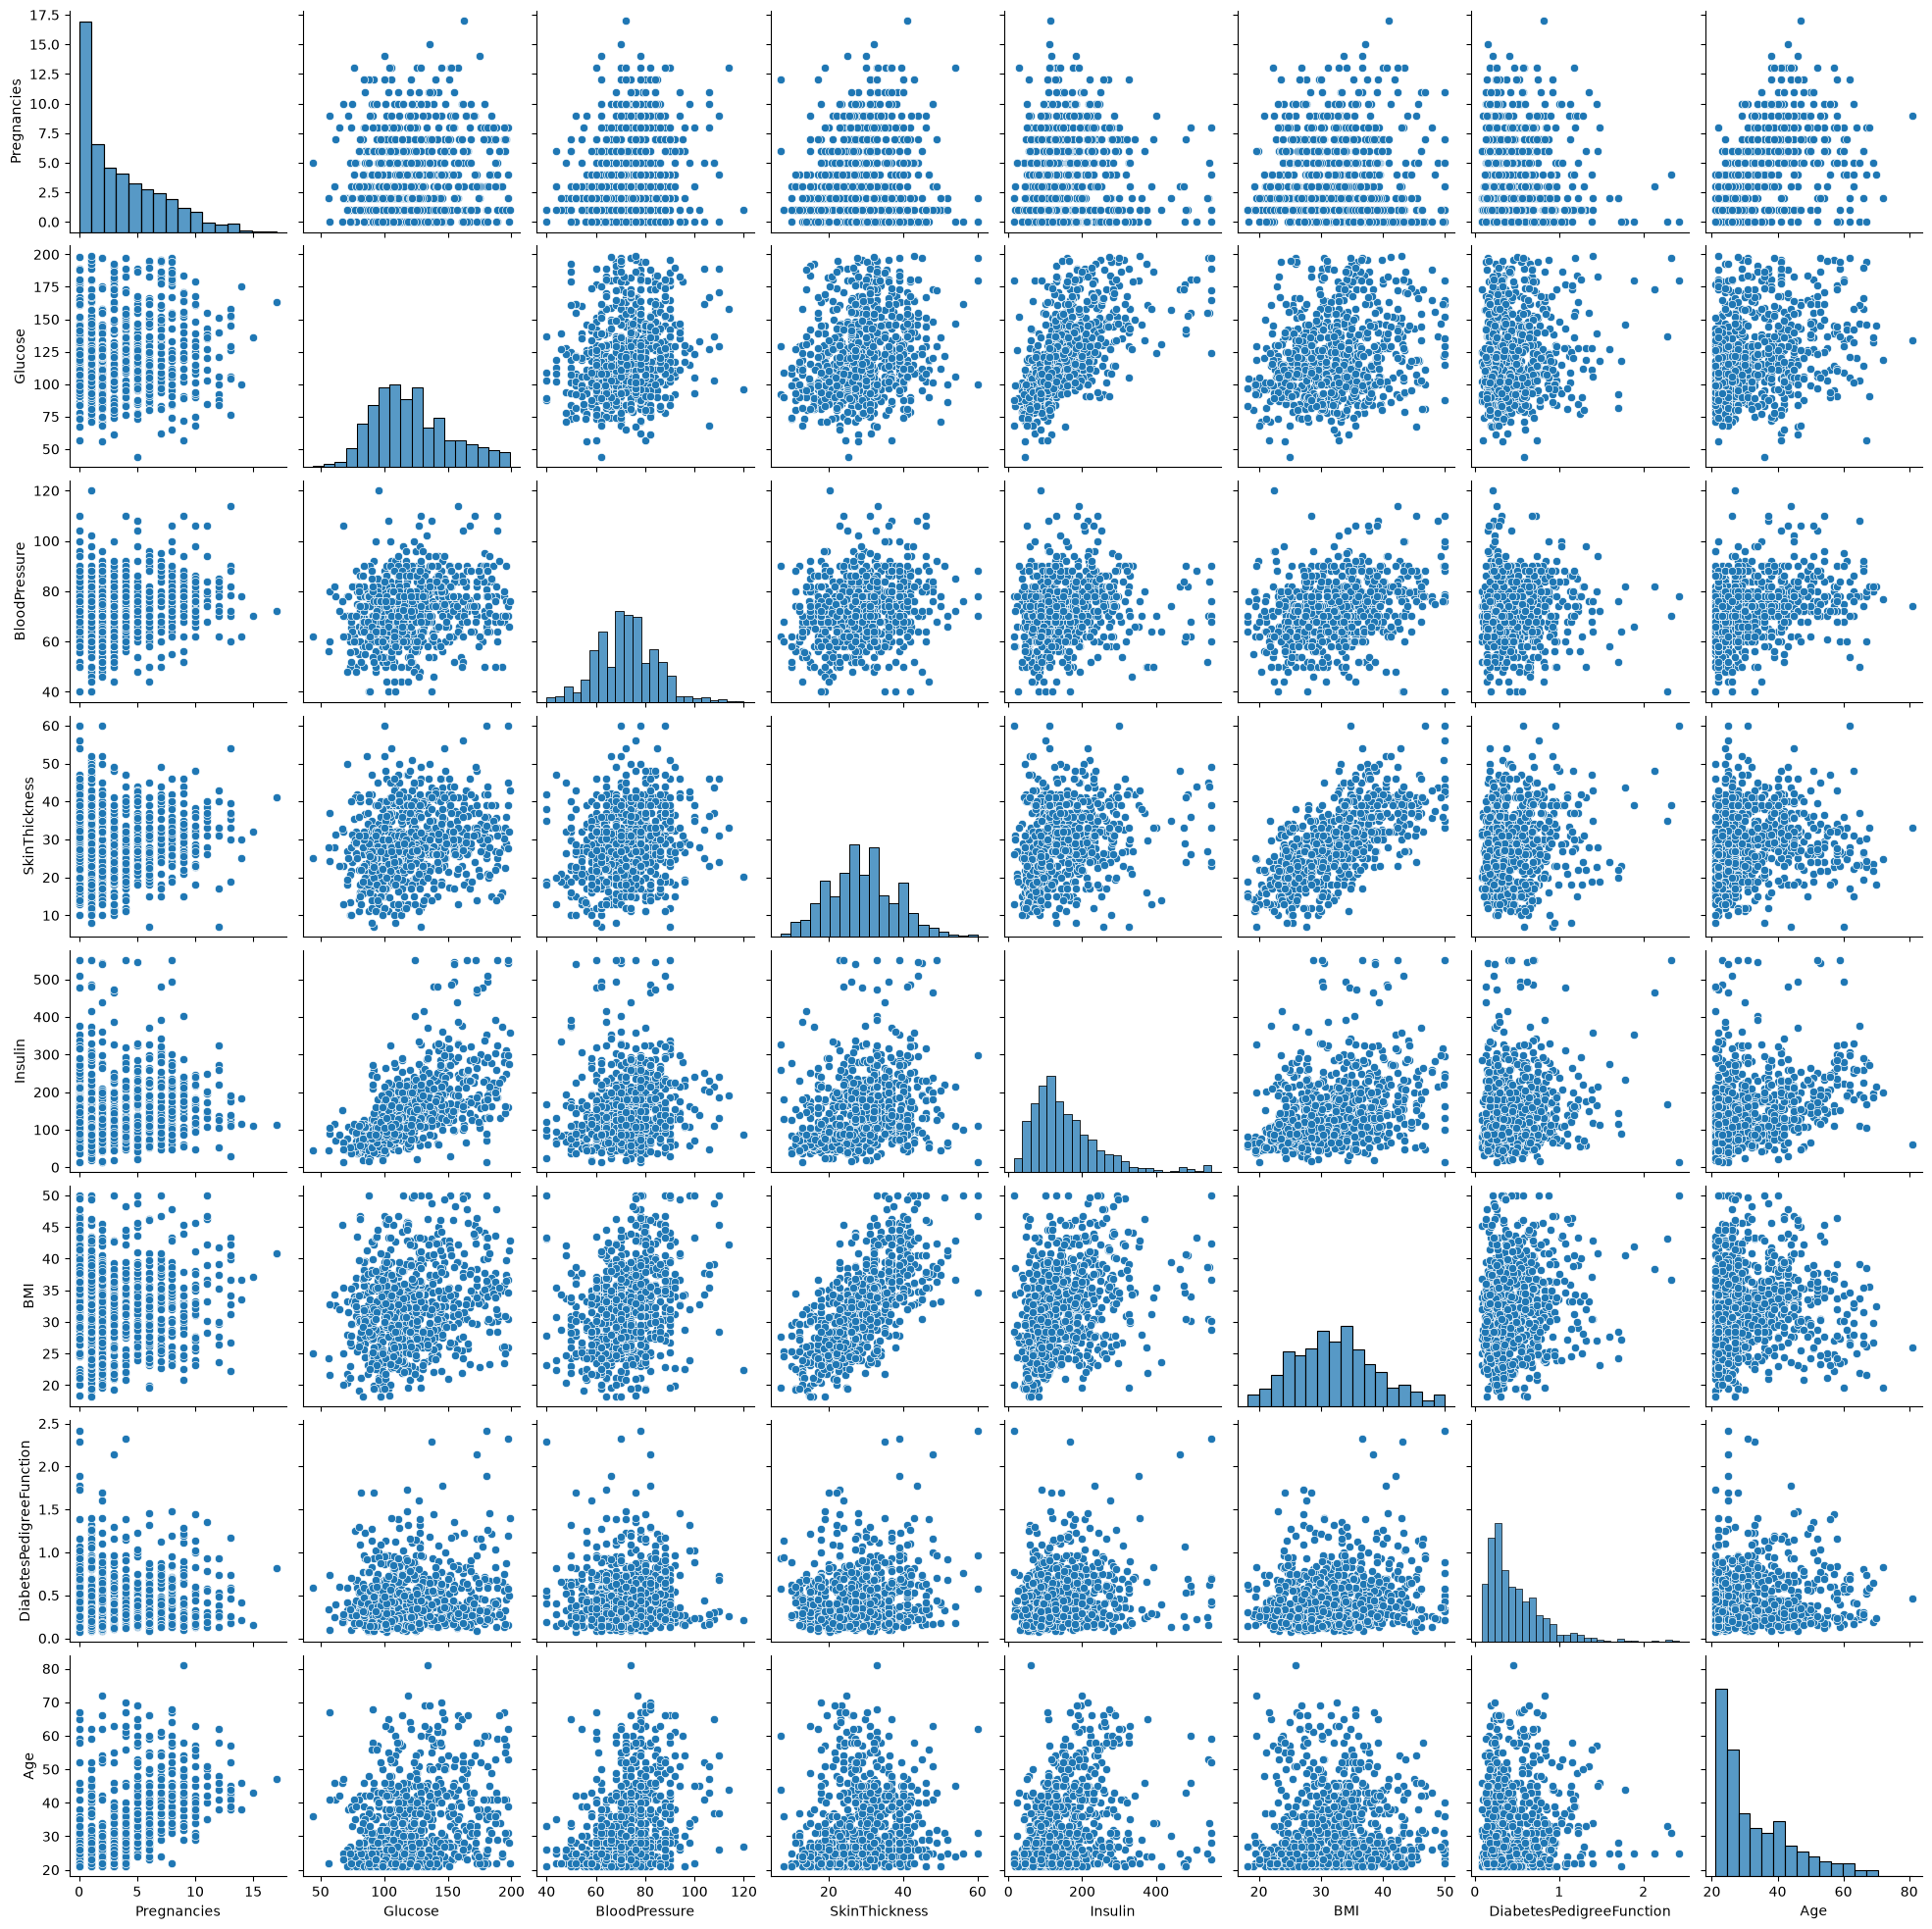

In [11]:
sns.pairplot(df)
plt.show()

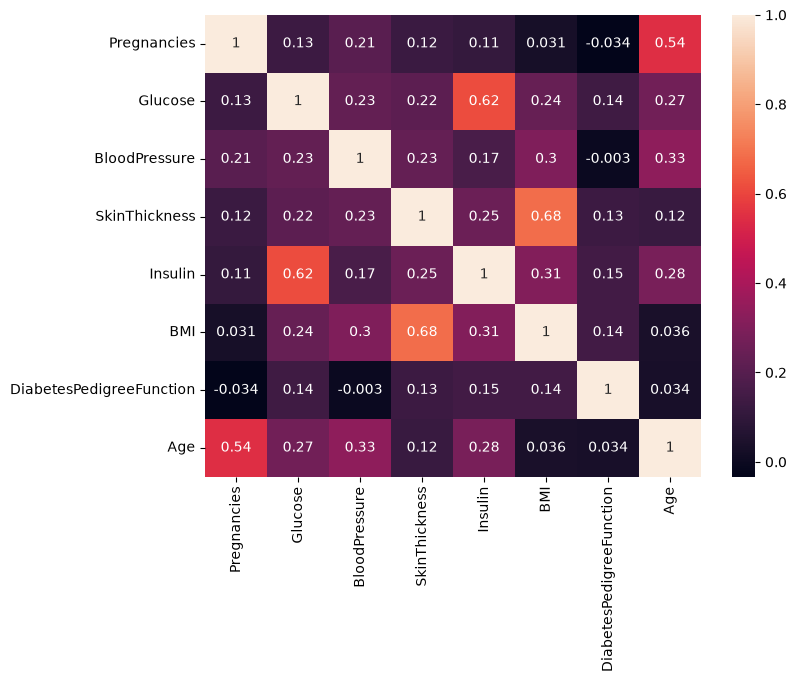

In [12]:
corr = df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True)
plt.show()

In [13]:
cv = df.std() / df.mean()
print(cv.sort_values(ascending=False))

Pregnancies                 0.876341
DiabetesPedigreeFunction    0.702151
Insulin                     0.608869
Age                         0.353788
SkinThickness               0.317054
Glucose                     0.250616
BMI                         0.206278
BloodPressure               0.166021
dtype: float64


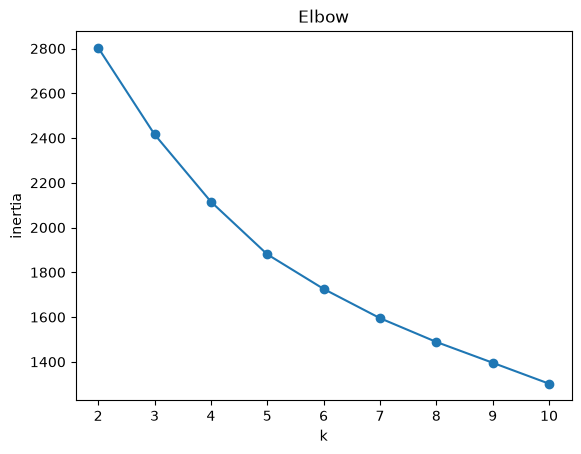

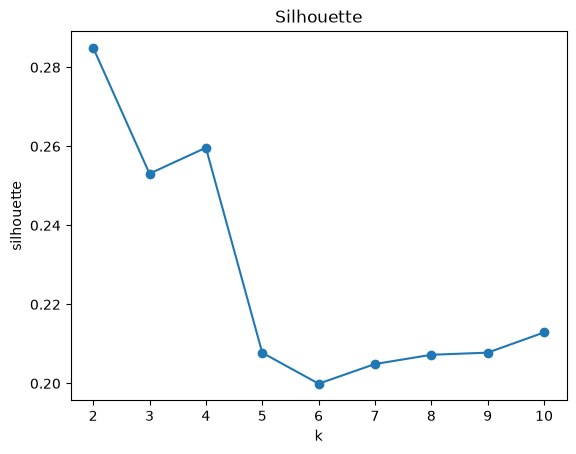

In [14]:
km_cols=["Glucose", "Insulin", "BMI", "Age", "DiabetesPedigreeFunction"]
scaler_km = StandardScaler()
X_scaled = scaler_km.fit_transform(df[km_cols])

inertias = []
silhouettes = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    inertias.append(km.inertia_)
    silhouettes.append(score)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.title("Elbow")
plt.show()

plt.plot(k_values, silhouettes, marker="o")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.title("Silhouette")
plt.show()

In [15]:

score = silhouette_score(X_scaled, labels)
print(score)

0.21289592622156187


In [16]:
km = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = km.fit_predict(X_scaled)

df_clustered = df.copy()
df_clustered["cluster"] = labels

print(df_clustered["cluster"].value_counts())
print(df_clustered.groupby("cluster").mean())

cluster
1    475
0    293
Name: count, dtype: int64
         Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
cluster                                                                      
0           4.996587  148.531058      77.034130      32.405461  229.509215   
1           3.134737  104.978526      69.595789      26.808842  105.470737   

               BMI  DiabetesPedigreeFunction        Age  
cluster                                                  
0        35.474608                  0.571908  40.819113  
1        30.445179                  0.410173  28.566316  


In [17]:

df_clustered["risk_category"] = df_clustered["cluster"].map(
    {0: "high risk", 1: "low risk"})

print(df_clustered["risk_category"].value_counts())
df_clustered.head()

risk_category
low risk     475
high risk    293
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,cluster,risk_category
0,6.0,148.0,72.0,35.0,264.8,33.6,0.627,50.0,0,high risk
1,1.0,85.0,66.0,29.0,65.2,26.6,0.351,31.0,1,low risk
2,8.0,183.0,64.0,30.6,198.2,23.3,0.672,32.0,0,high risk
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,1,low risk
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,0,high risk


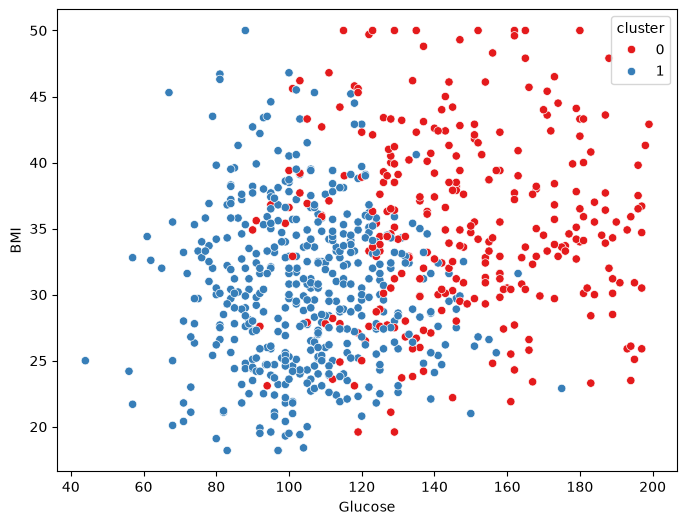

In [18]:
plt.figure(figsize=(8, 6))
df["cluster"] = labels
sns.scatterplot(data=df, x="Glucose", y="BMI", hue="cluster", palette="Set1")
plt.show()

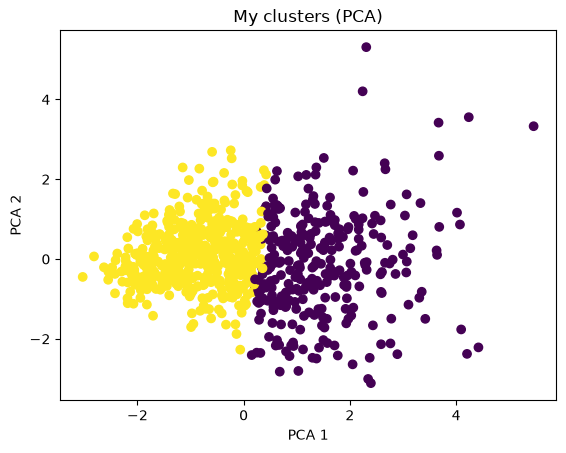

In [19]:


pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("My clusters (PCA)")
plt.show()

In [20]:
loadings = pd.DataFrame(pca.components_, columns=km_cols, index=["PCA 1", "PCA 2"])
print(loadings)

        Glucose   Insulin      BMI       Age  DiabetesPedigreeFunction
PCA 1  0.579071  0.598414  0.36581  0.345470                  0.231108
PCA 2 -0.126423 -0.082868  0.48281 -0.581803                  0.636828


In [21]:
df_clustered.groupby("risk_category")[["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]].mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
risk_category,,,,,,,,
high risk,4.996587,148.531058,77.034130,32.405461,229.509215,35.474608,0.571908,40.819113
low risk,3.134737,104.978526,69.595789,26.808842,105.470737,30.445179,0.410173,28.566316


In [22]:
df_clustered.drop(columns="cluster", inplace=True)

In [23]:
from sklearn.neighbors import KNeighborsClassifier


X = df_clustered[cols]
y = df_clustered["risk_category"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression())]),
    "Random Forest": Pipeline([("scaler", StandardScaler()), ("model", RandomForestClassifier(random_state=42))]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("model", SVC())]),
    "KNeighbors": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=5))]),
}

for name in models:
    clf = models[name]
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)
    print(name)
    print(confusion_matrix(y_test, predictions))
    print(classification_report(y_test, predictions))

Logistic Regression
[[57  2]
 [ 0 95]]
              precision    recall  f1-score   support

   high risk       1.00      0.97      0.98        59
    low risk       0.98      1.00      0.99        95

    accuracy                           0.99       154
   macro avg       0.99      0.98      0.99       154
weighted avg       0.99      0.99      0.99       154

Random Forest
[[53  6]
 [ 4 91]]
              precision    recall  f1-score   support

   high risk       0.93      0.90      0.91        59
    low risk       0.94      0.96      0.95        95

    accuracy                           0.94       154
   macro avg       0.93      0.93      0.93       154
weighted avg       0.93      0.94      0.93       154

SVM
[[54  5]
 [ 5 90]]
              precision    recall  f1-score   support

   high risk       0.92      0.92      0.92        59
    low risk       0.95      0.95      0.95        95

    accuracy                           0.94       154
   macro avg       0.93      0.93

In [ ]:
param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
}

lr_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression())]),
    param_grid_lr,
    cv=5,
    scoring="f1_weighted"
)
lr_search.fit(X_train, y_train)
print(lr_search.best_params_)

best_lr = lr_search.best_estimator_
predictions = best_lr.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

{'model__C': 1000}
[[58  1]
 [ 0 95]]
              precision    recall  f1-score   support

   high risk       1.00      0.98      0.99        59
    low risk       0.99      1.00      0.99        95

    accuracy                           0.99       154
   macro avg       0.99      0.99      0.99       154
weighted avg       0.99      0.99      0.99       154



In [25]:


mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("diabetes-risk")


trusted_types = [
    "sklearn.tree._tree.Tree",
    "sklearn.neighbors._kd_tree.KDTree",
    "sklearn.metrics._dist_metrics.EuclideanDistance64",
]

for name in models:
    clf = models[name]
    with mlflow.start_run(run_name=name):
        clf.fit(X_train, y_train)
        pred = clf.predict(X_test)

        mlflow.log_param("model", name)
        mlflow.log_metric("accuracy", accuracy_score(y_test, pred))
        mlflow.log_metric("f1_weighted", f1_score(y_test, pred, average="weighted"))
        mlflow.log_metric("recall_high_risk", recall_score(y_test, pred, pos_label="high risk"))
        mlflow.sklearn.log_model(clf, name="model", skops_trusted_types=trusted_types)

with mlflow.start_run(run_name="Logistic Regression tuned"):
    pred = best_lr.predict(X_test)

    mlflow.log_param("model", "Logistic Regression tuned")
    mlflow.log_param("C", lr_search.best_params_["model__C"])
    mlflow.log_metric("accuracy", accuracy_score(y_test, pred))
    mlflow.log_metric("f1_weighted", f1_score(y_test, pred, average="weighted"))
    mlflow.log_metric("recall_high_risk", recall_score(y_test, pred, pos_label="high risk"))
    mlflow.sklearn.log_model(best_lr, name="model", skops_trusted_types=trusted_types)

In [26]:
runs = mlflow.search_runs(experiment_names=["diabetes-risk"], order_by=["metrics.recall_high_risk DESC"])
print(runs[["run_id", "tags.mlflow.runName", "metrics.recall_high_risk", "metrics.accuracy"]])

                              run_id        tags.mlflow.runName  \
0   ebcf799b632e4ce79fe4b1fb5bdeed68  Logistic Regression tuned   
1   f83adf5af02c45b2ae02adffdb7306d5  Logistic Regression tuned   
2   ececb25af52746eea19bad86c1864ab8  Logistic Regression tuned   
3   87e015365c1c4737947ef7d75200161d  Logistic Regression tuned   
4   4fe24c6fa6a4444f99d2ad00a2520003        Logistic Regression   
5   61fd77da1218410c925ddb18311f150c        Logistic Regression   
6   b4c7f158f9bb4ef192db1a360048c45b        Logistic Regression   
7   18b94bde5b92470e832bf5b6cf3ede31        Logistic Regression   
8   7231f131af4f4ad58d2f21f3566f9e17                        SVM   
9   5ec6c82b779a44639134344ebcff183f                        SVM   
10  d3b00739280c4b1ab4165c8f58211d94                        SVM   
11  d13ebdca7ba44b39974e23f93f6c3981                        SVM   
12  d5d202cbb86a4b60bf219767c9577280              Random Forest   
13  0c83efee682b4721bfd98909bae313fa              Random Fores

In [27]:
# Model registration is handled in src/train.py
best = runs[runs["tags.mlflow.runName"] == "Logistic Regression tuned"]
best_run_id = best.iloc[0]["run_id"]
print("Best run:", best_run_id)


In [28]:
# Alias champion and stage Production are registered via src/train.py
print("Registered model name: diabetes-risk-classifier (alias: champion)")


In [29]:
# Tracking URI check (model loading is verified in api/main.py)
print(mlflow.get_tracking_uri())
print(mlflow.search_experiments())
